In [1]:
#funções para incializar
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

def dixon(s23,s46):
    
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2
         
    ff = rf / (rf + rw)
    
    return(ff)

## Como o sinal da gordura interfere no sinal GRE , dada ausência de efeito T2*?
### Simulação 7 ecos, FF [1-99%], T2\* *infinito*.

Objetivo: 
* Verificar a relação entre a presença de gordura e a intensidade do sinal, na  hipotética ausência de efeito T2*.

Parâmetros de simulação (sugeridos):
* Range de FF: 0.01 a 0.99, em 10 iterações, somente para plotar (`FF = np.linspace(0.01, 0.99, 10)`) 
* T2\* = infinito (`np.inf`)
* Campo $B_{0}$ = 3T (`magField = 3.0`)
    - Embora os valores de frequência de precessão sejam calculados de acordo com o campo, os TE devem ser alterados manualmente.



FFreal = 0.01, FFdixon = 0.0080738615237091471, max-min = 0.0016117823811500481


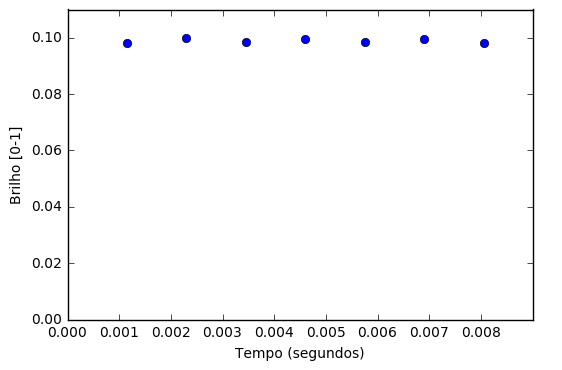

FFreal = 0.11888888888888888, FFdixon = 0.097973452796929691, max-min = 0.019164075180368084


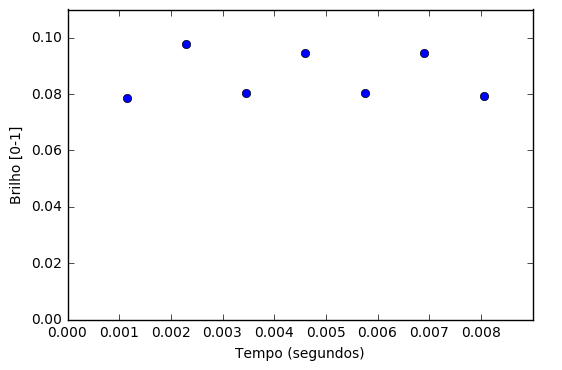

FFreal = 0.22777777777777777, FFdixon = 0.19164161879621508, max-min = 0.036717419481885949


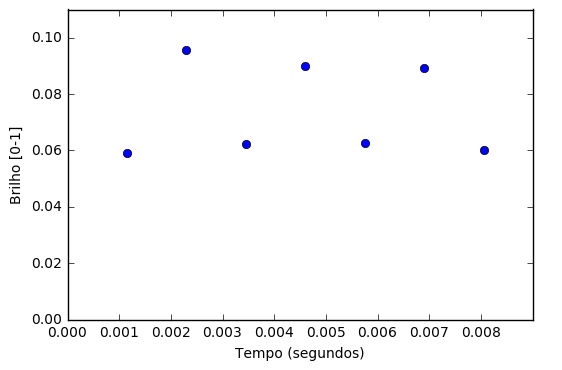

FFreal = 0.33666666666666667, FFdixon = 0.28925135318898382, max-min = 0.054263213240074805


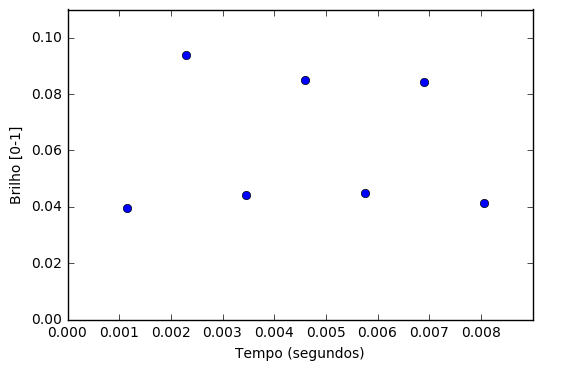

FFreal = 0.44555555555555554, FFdixon = 0.39079449197841171, max-min = 0.071757561815248352


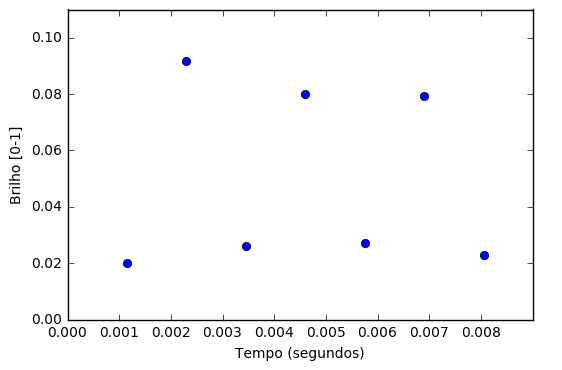

FFreal = 0.55444444444444441, FFdixon = 0.48490278099663259, max-min = 0.087116591873252422


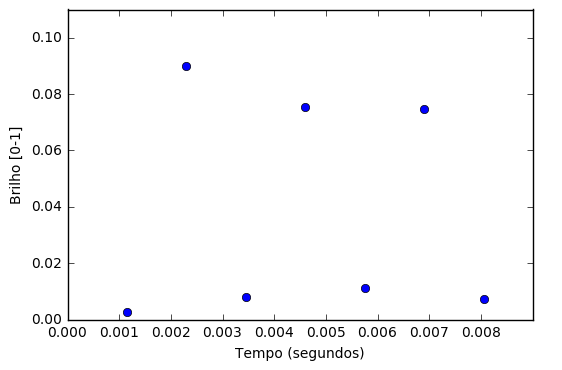

FFreal = 0.66333333333333333, FFdixon = 0.38922179662311202, max-min = 0.0778390387998492


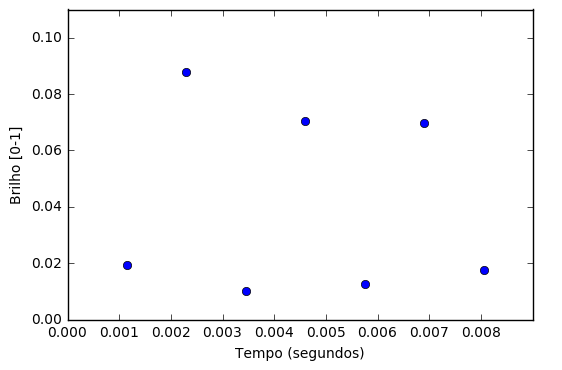

FFreal = 0.77222222222222214, FFdixon = 0.27329930951913206, max-min = 0.057823603083901207


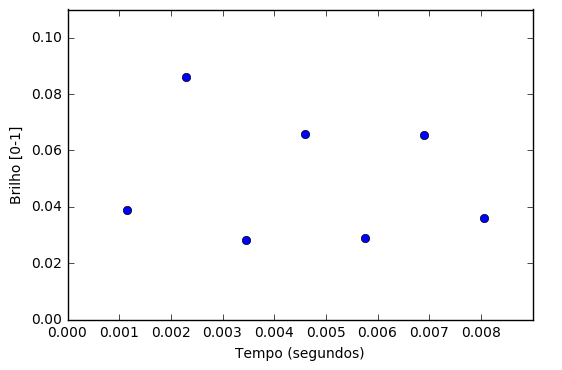

FFreal = 0.88111111111111107, FFdixon = 0.15162684306036059, max-min = 0.037814873406899506


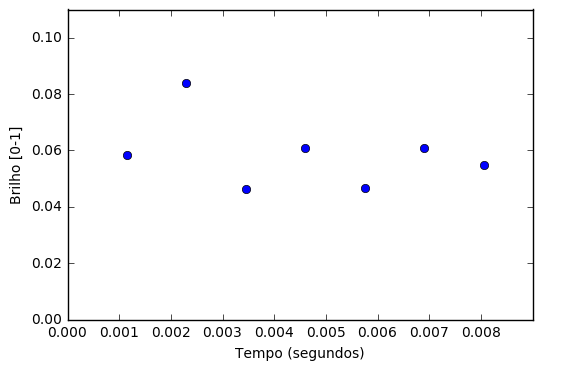

FFreal = 0.98999999999999999, FFdixon = 0.024133462881276584, max-min = 0.025829966094535216


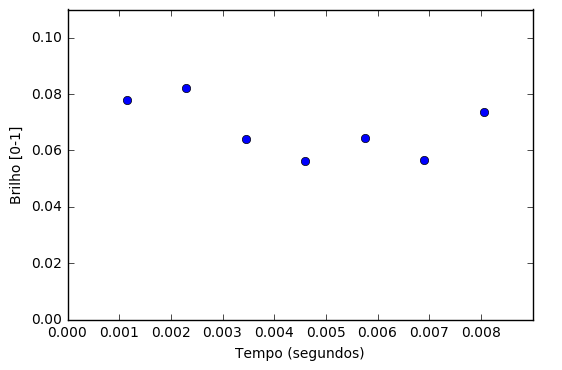

In [2]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

#valores de %FF: (inicial, final e numero de valores)
FF = np.linspace(0.01, 0.99, 10)

#para plotar somente os 7 pontos, use este t (em 3 Tesla)
t = [0.0011515,  \
0.0011515*2,\
0.0011515*3,\
0.0011515*4,\
0.0011515*5,\
0.0011515*6,\
0.0011515*7]
t = np.array(t)

"""
#para plotar a curva toda
t = np.linspace(0, 0.05, 1000)
"""

# t2star nesse caso eh definido como np.inf na equacao
# t2star = [0.030,\
# 0.040,\
# 0.051,\
# 0.052,\
# 0.062,\
# 0.083,\
# 0.023]
#t2star = np.array(t2star)

#frequencia relativa agua/gordura em ppm
Fppmn = [5.3,\
4.2,\
2.75,\
2.1,\
1.3,\
0.9,\
4.7]
Fppmn = np.array(Fppmn)

#calculo da frequencia relativa agua/gordura
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = [0,0,0,0,0,0,0]
freq = np.array(freq)
for n in range(0,len(Fppmn)):
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

#inicialização dos arrays que receberão os sinais (temporario e final)
S = (len(Fppmn),len(t)) #num. linhas: qtde de componentes; num. col: qtde de pontos t
S = np.zeros(S,dtype='complex')
Sfinal= (len(t))
Sfinal=np.zeros(Sfinal,dtype='complex')

for fatPercent in FF:

    rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water
    rho = np.array(rho)

    for n in range(0,len(Fppmn)):
        for index,TE in enumerate(t):
            S[n,index] = 0.1*rho[n]*np.exp(-TE/np.inf)*np.exp(2.0*np.pi*1j*freq[n]*TE) #0.1 é p/ escala       
    
    Sfinal = np.sum(S, axis=0)
    Sfinal = np.absolute(Sfinal)
    FFdixon = dixon(Sfinal[0],Sfinal[1])
    diff = max(Sfinal)-min(Sfinal)
    
    plt.plot(t, Sfinal,'o')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Brilho [0-1]')
    plt.axis([0.0, 0.009, 0.00, 0.11])
    print("FFreal = %r, FFdixon = %r, max-min = %r" % (fatPercent, FFdixon, diff))
    plt.show()

Uma inspeção inicial dos gráficos mostra que até FF = 50%, a distância os pontos de max-min, TE2-TE1 para estes valores de gordura, parece crescer linearmente. A partir de 50% de conteúdo lipídico, a relação entre os pontos max-min, que já não são mais TE2-TE1, deixa de crescer linearmente, podendo decrescer. Os pontos TE2-TE1 também tornam a decrescer partir de 50%FF, contribuindo com o efeito de ambuiguidade da á4gua e gordura para imagens de módulo, em especial no cálculo por Dixon que utiliza apenas estes dois pontos.

Algumas considerações a respeito do formato dos sinais obtidos para todos os 7 pontos:
Até 50%FF há um aumento na distância entre os pontos OP (inferiores) e IP (superiores), após este valor, parece haver uma inversão no formato dos pontos OP (lobo inferior) e minimização do sinal IP. 
Isso se deve ao fato de o sinal ser formado por uma soma de componentes senoidais em frequências diferentes, com diferentes amplitudes dominantes de acordo com a %FF escolhida. **Talvez a ideia de formato (*feature*) do sinal em diferentes %FF pode ser utilizada para obter a gordura a gordura por técnicas de aprendizado de máquina para quantificar de 0 a 100% com imagem de módulo?**

## Como o efeito T2\* (igual para todos) interfere na forma do sinal GRE, para valores fixos de %FF?
### Simulação 7 ecos, FF [0-99%], T2\* = 0.023 e 0.053.

Objetivo: 
* Verificar a relação entre a presença de gordura e a intensidade do sinal, na  hipotética ausência de efeito T2*.

T2* = 0.083000000000000004 para todos os componentes
FFreal = 0.01, FFdixon = 0.0012015660578307847, max-min = 0.0079223257518862694


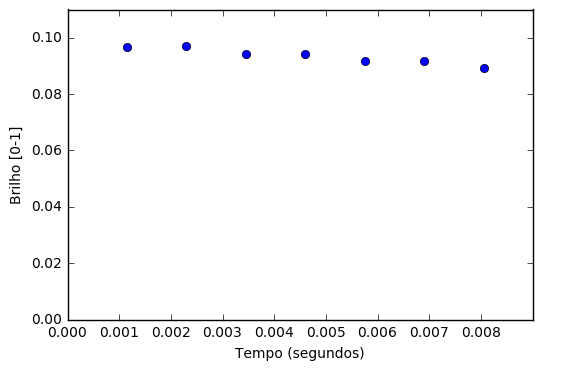

FFreal = 0.11888888888888888, FFdixon = 0.092357070577305841, max-min = 0.023204810388911798


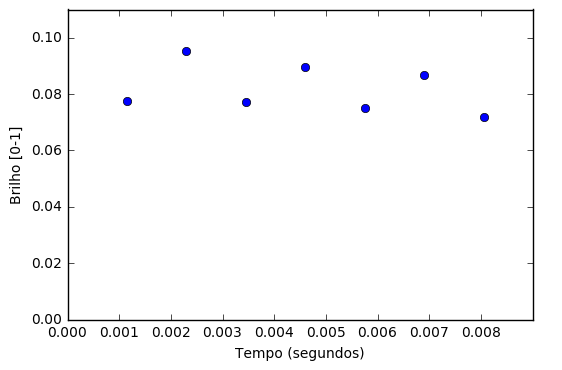

FFreal = 0.22777777777777777, FFdixon = 0.18733379748064874, max-min = 0.038463226401348284


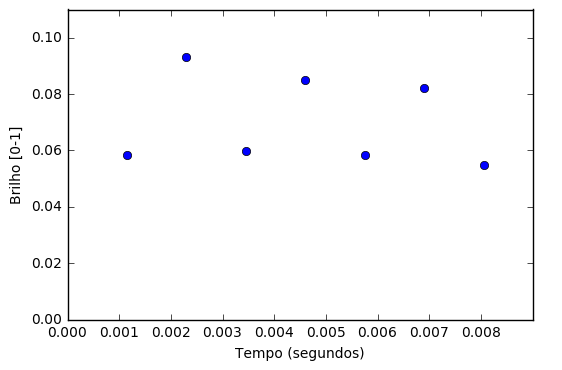

FFreal = 0.33666666666666667, FFdixon = 0.28630715718751609, max-min = 0.053655365931873915


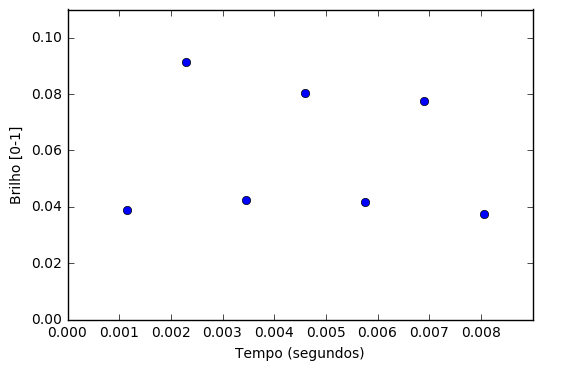

FFreal = 0.44555555555555554, FFdixon = 0.38926887164859891, max-min = 0.069521406897343124


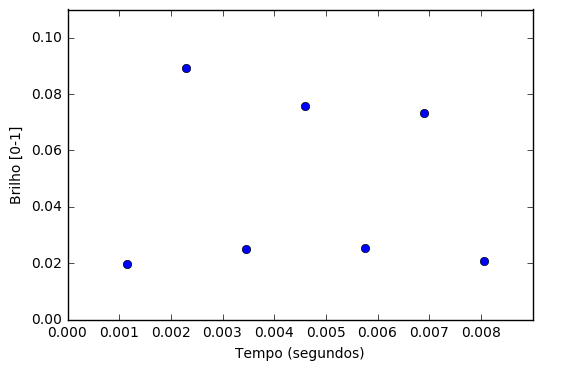

FFreal = 0.55444444444444441, FFdixon = 0.48469187016756882, max-min = 0.084695741292903443


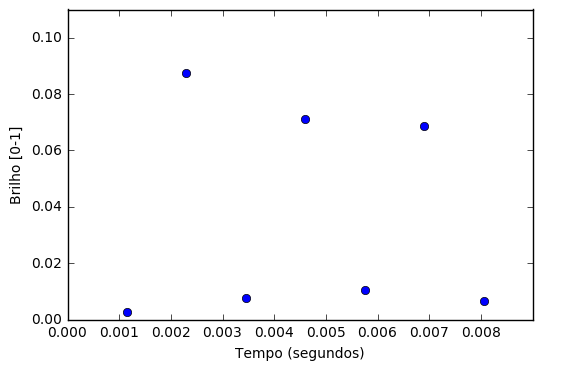

FFreal = 0.66333333333333333, FFdixon = 0.38767420546004994, max-min = 0.075843179295855018


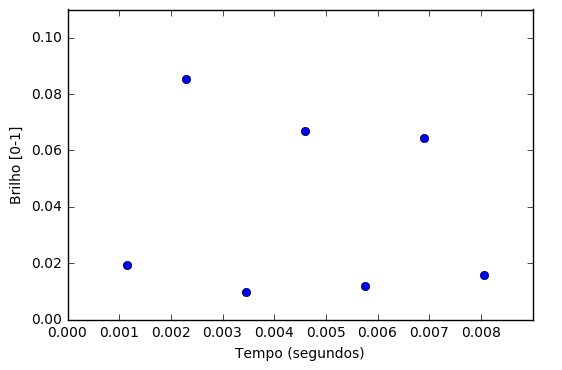

FFreal = 0.77222222222222214, FFdixon = 0.27013226063628776, max-min = 0.056617408139408548


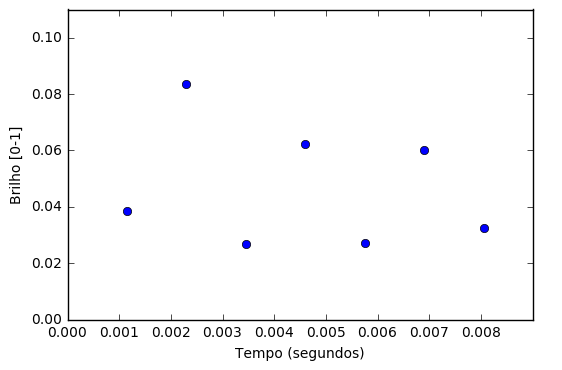

FFreal = 0.88111111111111107, FFdixon = 0.1467600082255911, max-min = 0.038227115439025933


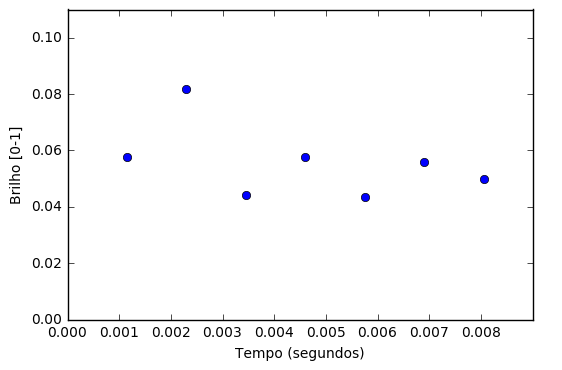

FFreal = 0.98999999999999999, FFdixon = 0.017485522896762196, max-min = 0.02766937937871055


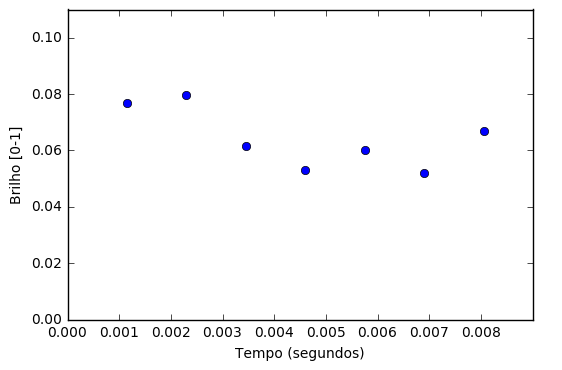

In [3]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

#valores de %FF: (inicial, final e numero de valores)
FF = np.linspace(0.01, 0.99, 10)

#para plotar somente os 7 pontos, use este t (em 3 Tesla)
t = [0.0011515,  \
0.0011515*2,\
0.0011515*3,\
0.0011515*4,\
0.0011515*5,\
0.0011515*6,\
0.0011515*7]
t = np.array(t)

"""
#para plotar a curva toda
t = np.linspace(0, 0.05, 1000)
"""

t2star = [0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023]

t2star = [0.083,\
 0.083,\
 0.083,\
 0.083,\
 0.083,\
 0.083,\
 0.083]
t2star = np.array(t2star)
print("T2* = %r para todos os componentes" % (t2star[0]))

#frequencia relativa agua/gordura em ppm
Fppmn = [5.3,\
4.2,\
2.75,\
2.1,\
1.3,\
0.9,\
4.7]
Fppmn = np.array(Fppmn)

#calculo da frequencia relativa agua/gordura
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = [0,0,0,0,0,0,0]
freq = np.array(freq)
for n in range(0,7):
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

#inicialização dos arrays que receberão os sinais (temporario e final)
S = (len(Fppmn),len(t)) #num. linhas: qtde de componentes; num. col: qtde de pontos t
S = np.zeros(S,dtype='complex')
Sfinal= (len(t))
Sfinal=np.zeros(Sfinal,dtype='complex')

for fatPercent in FF:

    rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water
    rho = np.array(rho)

    for n in range(0,len(Fppmn)):
        for index,TE in enumerate(t):
            S[n,index] = 0.1*rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE) #0.1 é p/ escala       
    
    Sfinal = np.sum(S, axis=0)
    Sfinal = np.absolute(Sfinal)
    FFdixon = dixon(Sfinal[0],Sfinal[1])
    diff = max(Sfinal)-min(Sfinal)
    
    plt.plot(t, Sfinal,'o')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Brilho [0-1]')
    plt.axis([0.0, 0.009, 0.00, 0.11])
    print("FFreal = %r, FFdixon = %r, max-min = %r" % (fatPercent, FFdixon, diff))
    plt.show()

T2* = 0.023 para todos os componentes
FFreal = 0.01, FFdixon = -0.017181459057742737, max-min = 0.024200551942649959


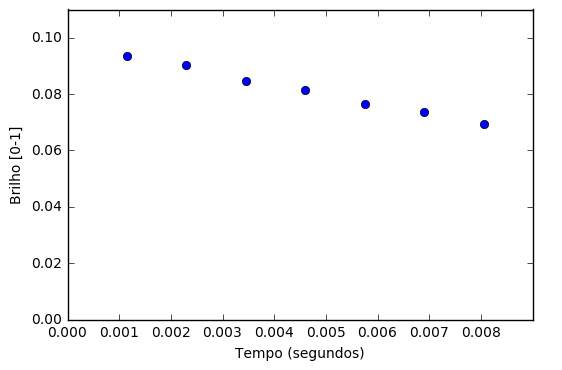

FFreal = 0.11888888888888888, FFdixon = 0.077333546644926976, max-min = 0.032658347232248072


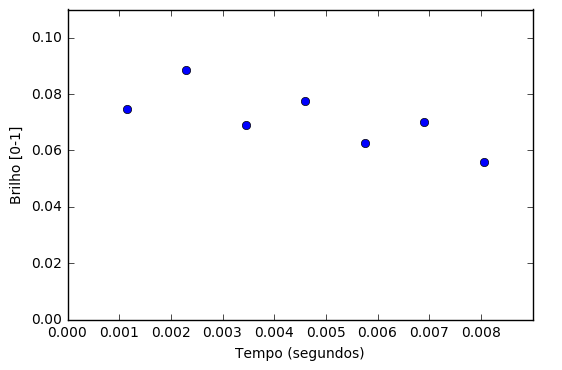

FFreal = 0.22777777777777777, FFdixon = 0.17581060441791646, max-min = 0.044201655549494574


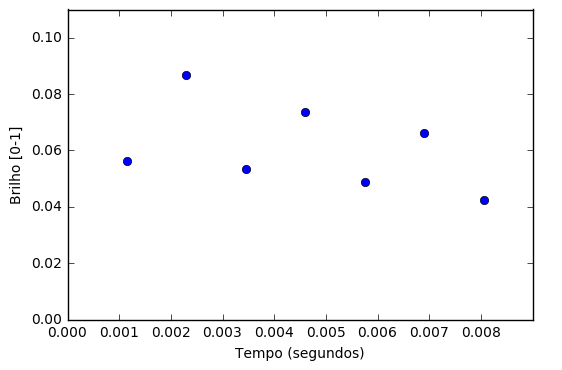

FFreal = 0.33666666666666667, FFdixon = 0.27843158936467155, max-min = 0.055694660337124204


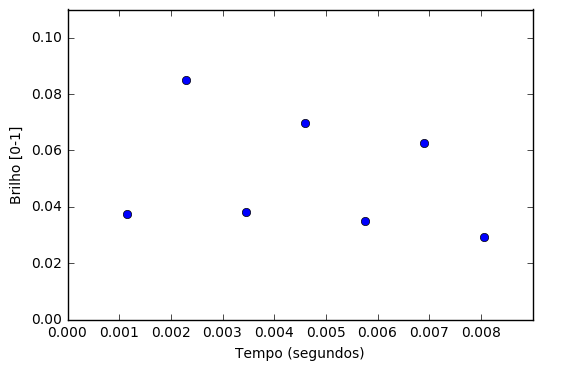

FFreal = 0.44555555555555554, FFdixon = 0.38518791835154903, max-min = 0.066995143732672471


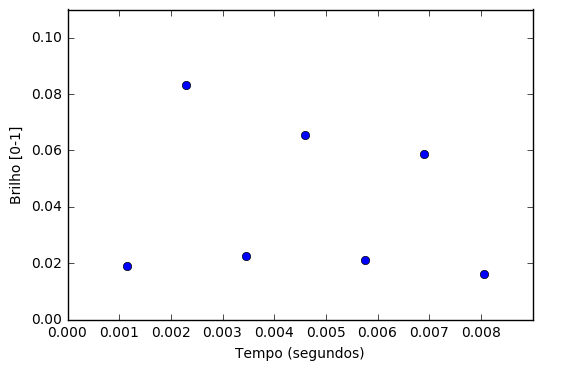

FFreal = 0.55444444444444441, FFdixon = 0.48412769490952318, max-min = 0.078690088581654313


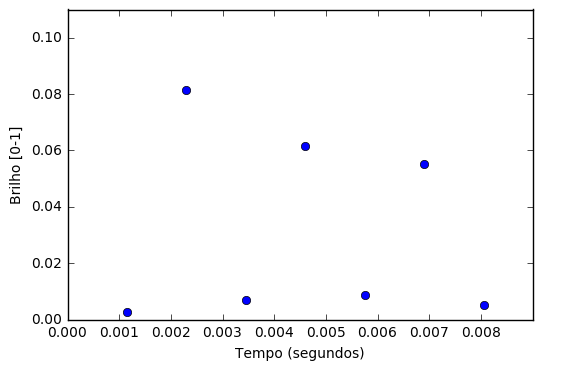

FFreal = 0.66333333333333333, FFdixon = 0.38353448135178614, max-min = 0.070865091201847863


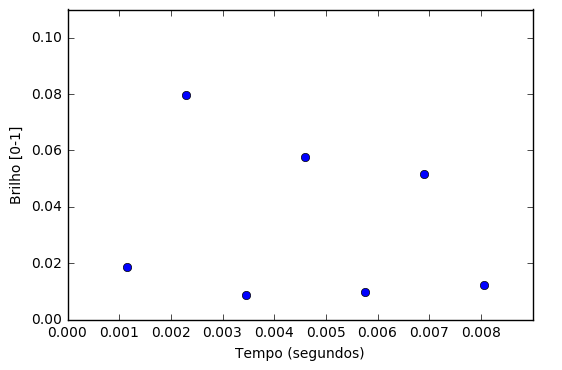

FFreal = 0.77222222222222214, FFdixon = 0.26166057320016994, max-min = 0.055165324664735935


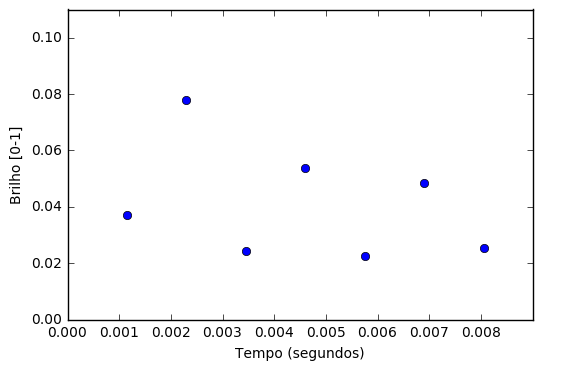

FFreal = 0.88111111111111107, FFdixon = 0.13374148371000139, max-min = 0.039713344087063653


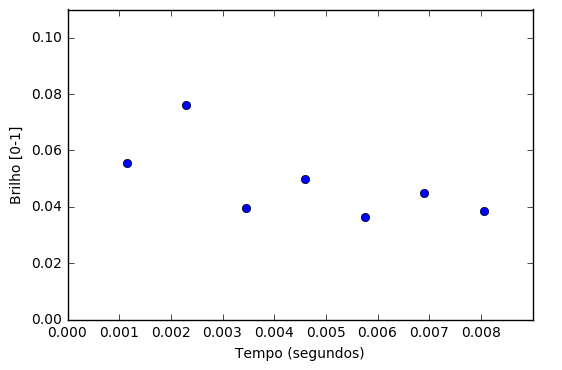

FFreal = 0.98999999999999999, FFdixon = -0.00029736323043227469, max-min = 0.032311837316804599


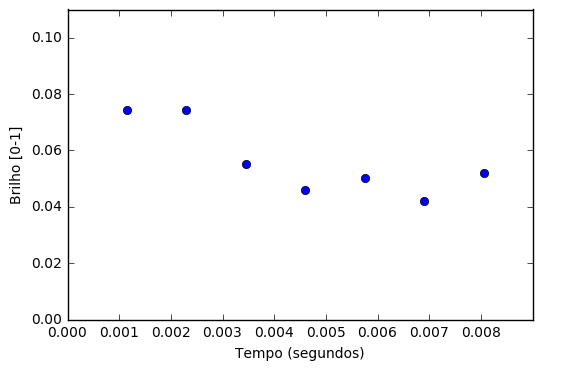

In [4]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

#valores de %FF: (inicial, final e numero de valores)
FF = np.linspace(0.01, 0.99, 10)

#para plotar somente os 7 pontos, use este t (em 3 Tesla)
t = [0.0011515,  \
0.0011515*2,\
0.0011515*3,\
0.0011515*4,\
0.0011515*5,\
0.0011515*6,\
0.0011515*7]
t = np.array(t)

"""
#para plotar a curva toda
t = np.linspace(0, 0.05, 1000)
"""

t2star = [0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023,\
 0.023]

t2star = np.array(t2star)
print("T2* = %r para todos os componentes" % (t2star[0]))

#frequencia relativa agua/gordura em ppm
Fppmn = [5.3,\
4.2,\
2.75,\
2.1,\
1.3,\
0.9,\
4.7]
Fppmn = np.array(Fppmn)

#calculo da frequencia relativa agua/gordura
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = [0,0,0,0,0,0,0]
freq = np.array(freq)
for n in range(0,7):
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

#inicialização dos arrays que receberão os sinais (temporario e final)
S = (len(Fppmn),len(t)) #num. linhas: qtde de componentes; num. col: qtde de pontos t
S = np.zeros(S,dtype='complex')
Sfinal= (len(t))
Sfinal=np.zeros(Sfinal,dtype='complex')

for fatPercent in FF:

    rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water
    rho = np.array(rho)

    for n in range(0,len(Fppmn)):
        for index,TE in enumerate(t):
            S[n,index] = 0.1*rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE) #0.1 é p/ escala       
    
    Sfinal = np.sum(S, axis=0)
    Sfinal = np.absolute(Sfinal)
    FFdixon = dixon(Sfinal[0],Sfinal[1])
    diff = max(Sfinal)-min(Sfinal)
    
    plt.plot(t, Sfinal,'o')
    plt.xlabel('Tempo (segundos)')
    plt.ylabel('Brilho [0-1]')
    plt.axis([0.0, 0.009, 0.00, 0.11])
    print("FFreal = %r, FFdixon = %r, max-min = %r" % (fatPercent, FFdixon, diff))
    plt.show()

## adicionar ruido

## (teste) Observação do efeito do T2* (igual para todos) na intensidade do sinal, %FF = 0.1 e 0.9 


FF = 0.1 para todos os testes
As cores entre os gráficos não estão relacionadas


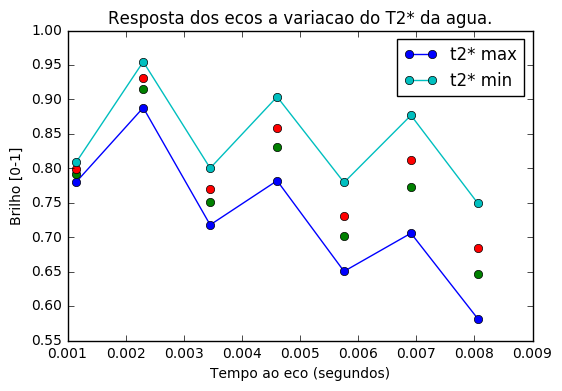

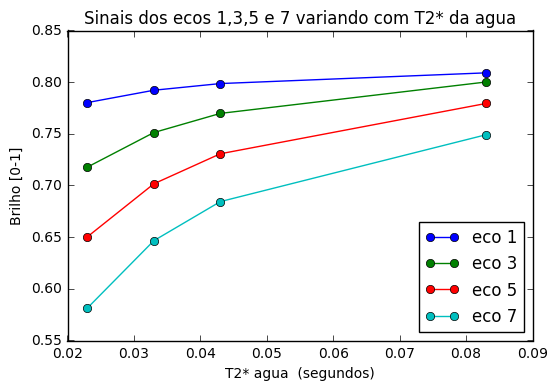

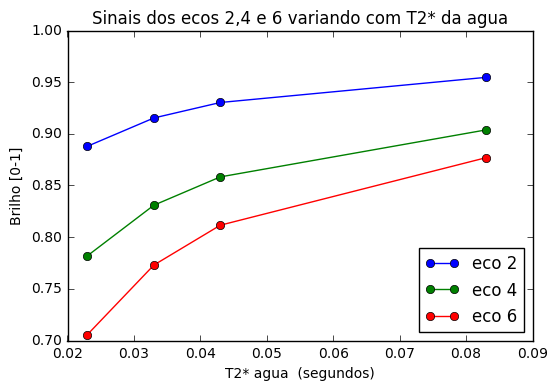

In [5]:
import numpy as np
import matplotlib.pyplot as plt

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

fatPercent = 0.1

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083]

t2starW = [0.023, 0.033, 0.043, 0.083]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Ssum= (7)
Ssum=np.zeros(Ssum,dtype='complex')
Sfinal = (4,7)
Sfinal = np.zeros(Sfinal)

for ind,t2w in enumerate(t2starW):
    for n in counter:
        for index,TE in enumerate(t):
            S[n,index] = rho[n]*np.exp(-TE/t2w)*np.exp(2.0*np.pi*1j*freq[n]*TE)         

    Ssum = np.sum(S, axis=0)
    Ssum = np.absolute(Ssum)
    #plt.xlabel('Tempo (segundos)')
    #plt.ylabel('Brilho [0-1]')
    #plt.show()
    Sfinal[ind,:] = Ssum

print("FF = %r para todos os testes" % (fatPercent))
print("As cores entre os gráficos não estão relacionadas")

#gráficos
plt.plot(t, Sfinal[0,:],'o-', label='t2* max')
plt.plot(t, Sfinal[1,:],'o')
plt.plot(t, Sfinal[2,:],'o')
plt.plot(t, Sfinal[3,:],'o-', label='t2* min')
plt.legend(loc='upper right')
plt.title('Resposta dos ecos a variacao do T2* da agua.')
plt.xlabel('Tempo ao eco (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


St1 = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]
St2 = [Sfinal[0,1],Sfinal[1,1],Sfinal[2,1],Sfinal[3,1]]
St3 = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
St6 = [Sfinal[0,5],Sfinal[1,5],Sfinal[2,5],Sfinal[3,5]]    
St5 = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
St4 = [Sfinal[0,3],Sfinal[1,3],Sfinal[2,3],Sfinal[3,3]]    
St7 = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]

plt.plot(t2starW, St1,'o-', label = "eco 1")
plt.plot(t2starW, St3,'o-', label = "eco 3")
plt.plot(t2starW, St5,'o-', label = "eco 5")
plt.plot(t2starW, St7,'o-', label = "eco 7")
plt.title('Sinais dos ecos 1,3,5 e 7 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()

plt.plot(t2starW, St2,'o-', label = "eco 2")
plt.plot(t2starW, St4,'o-', label = "eco 4")
plt.plot(t2starW, St6,'o-', label = "eco 6")

plt.title('Sinais dos ecos 2,4 e 6 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()


#gráficos SxT2, organizados por TE
# St = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do primeiro eco a variacao do T2* da agua (TE = 1.15 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do terceiro eco a variacao do T2* da agua (TE = 3.45 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do quinto eco agua variacao do T2* da agua (TE = 5.75 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do setimo eco a variacao do T2* da agua (TE = 8.05 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()


FF = 0.9 para todos os testes
As cores entre os gráficos não estão relacionadas


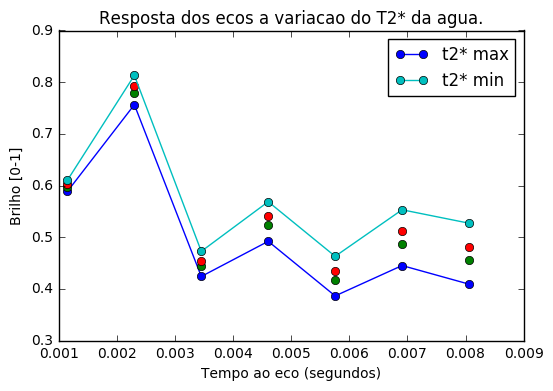

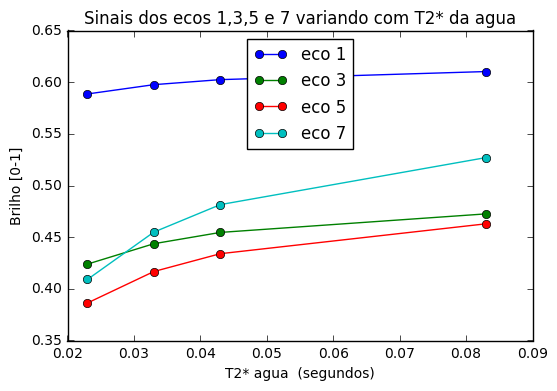

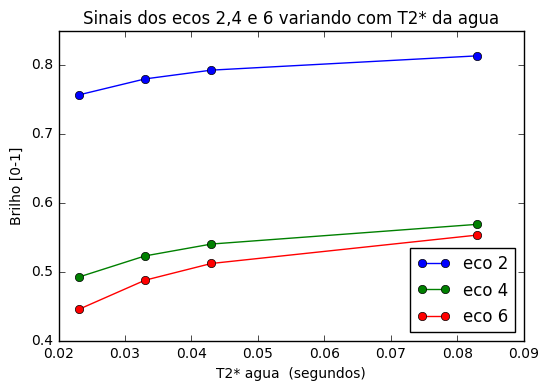

In [6]:
import numpy as np
import matplotlib.pyplot as plt

t = [0.0011515,  \
     0.0011515*2,\
     0.0011515*3,\
     0.0011515*4,\
     0.0011515*5,\
     0.0011515*6,\
     0.0011515*7]

fatPercent = 0.9

rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water

t2star = [0.030,\
          0.040,\
          0.051,\
          0.052,\
          0.062,\
          0.083]

t2starW = [0.023, 0.033, 0.043, 0.083]

Fppmn = [5.3,\
         4.2,\
         2.75,\
         2.1,\
         1.3,\
         0.9,\
         4.7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
t2star = np.array(t2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Ssum= (7)
Ssum=np.zeros(Ssum,dtype='complex')
Sfinal = (4,7)
Sfinal = np.zeros(Sfinal)

for ind,t2w in enumerate(t2starW):
    for n in counter:
        for index,TE in enumerate(t):
            S[n,index] = rho[n]*np.exp(-TE/t2w)*np.exp(2.0*np.pi*1j*freq[n]*TE)         

    Ssum = np.sum(S, axis=0)
    Ssum = np.absolute(Ssum)
    #plt.xlabel('Tempo (segundos)')
    #plt.ylabel('Brilho [0-1]')
    #plt.show()
    Sfinal[ind,:] = Ssum

print("FF = %r para todos os testes" % (fatPercent))
print("As cores entre os gráficos não estão relacionadas")

#gráficos
plt.plot(t, Sfinal[0,:],'o-', label='t2* max')
plt.plot(t, Sfinal[1,:],'o')
plt.plot(t, Sfinal[2,:],'o')
plt.plot(t, Sfinal[3,:],'o-', label='t2* min')
plt.legend(loc='upper right')
plt.title('Resposta dos ecos a variacao do T2* da agua.')
plt.xlabel('Tempo ao eco (segundos)')
plt.ylabel('Brilho [0-1]')
plt.show()


St1 = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]
St2 = [Sfinal[0,1],Sfinal[1,1],Sfinal[2,1],Sfinal[3,1]]
St3 = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
St6 = [Sfinal[0,5],Sfinal[1,5],Sfinal[2,5],Sfinal[3,5]]    
St5 = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
St4 = [Sfinal[0,3],Sfinal[1,3],Sfinal[2,3],Sfinal[3,3]]    
St7 = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]

plt.plot(t2starW, St1,'o-', label = "eco 1")
plt.plot(t2starW, St3,'o-', label = "eco 3")
plt.plot(t2starW, St5,'o-', label = "eco 5")
plt.plot(t2starW, St7,'o-', label = "eco 7")
plt.title('Sinais dos ecos 1,3,5 e 7 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()

plt.plot(t2starW, St2,'o-', label = "eco 2")
plt.plot(t2starW, St4,'o-', label = "eco 4")
plt.plot(t2starW, St6,'o-', label = "eco 6")

plt.title('Sinais dos ecos 2,4 e 6 variando com T2* da agua')
plt.xlabel('T2* agua  (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(loc='best')
plt.show()


#gráficos SxT2, organizados por TE
# St = [Sfinal[0,0],Sfinal[1,0],Sfinal[2,0],Sfinal[3,0]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do primeiro eco a variacao do T2* da agua (TE = 1.15 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,2],Sfinal[1,2],Sfinal[2,2],Sfinal[3,2]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do terceiro eco a variacao do T2* da agua (TE = 3.45 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,4],Sfinal[1,4],Sfinal[2,4],Sfinal[3,4]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do quinto eco agua variacao do T2* da agua (TE = 5.75 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()

# St = [Sfinal[0,6],Sfinal[1,6],Sfinal[2,6],Sfinal[3,6]]    
# print(St)
# plt.plot(t2starW, St,'o')
# plt.title('Resposta do setimo eco a variacao do T2* da agua (TE = 8.05 ms)')
# plt.xlabel('T2* agua  (segundos)')
# plt.ylabel('Brilho [0-1]')
# plt.show()


## *[próximo passo?]* Seria possível extrair características dos pontos/curvas para aprendizado de máquina calcular %FF?

* Pré estudo para observar padrões nas curvas
    - Curvas com diferentes %FF, sem efeito T2\* (como a gordura modela a forma?)
    - Curvas com iguais %FF, com efeito T2\* (como o T2\* altera a forma?)

In [7]:
t = np.linspace(0, 0.05, 1000)

